# Explore perturbation clusters

To find perturbations with similar profiles, start with the [browsable
Matches
tables](https://github.com/broadinstitute/monorepo/tree/main/libs/jump_rr#quick-data-access).
These show the top 100 most correlated/anticorrelated matches per
perturbation rather than the full all-vs-all matrix.

For comparisons outside those matches, the full cosine-similarity
matrices are available on [Zenodo](https://zenodo.org/records/20496083)
and mirrored on Cell Painting Gallery. Here we query the CRISPR matrix
to compare three perturbations without loading the entire matrix into
memory.

------------------------------------------------------------------------

In [1]:
from random import choices, seed

import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

We use a versioned Cell Painting Gallery mirror of the Zenodo release
for reproducibility and faster HTTP range reads. Polars can read the
metadata and selected columns without downloading the full 239 MB file.
Avoid calling `head().collect()` on the full-width matrix: even a few
rows would request all 7,977 columns.

The stored values are **cosine similarities**: 1 means profiles point in
the same direction, 0 means they are orthogonal, and -1 means they point
in opposite directions. Cosine distance, if needed, is `1 - similarity`.

In [2]:
ZENODO_RECORD_ID = "20496083"
CPG_BASE = (
    "https://cellpainting-gallery.s3.amazonaws.com/"
    "cpg0042-chandrasekaran-jump/source_all/workspace/publication_data/jump_rr"
)
similarities = pl.scan_parquet(
    f"{CPG_BASE}/{ZENODO_RECORD_ID}/crispr_cosinesim_full.parquet/content"
)

Columns are JUMP IDs (`JCP2022_X`), and rows follow the same order. See
the metadata tutorial for mapping these IDs to gene names. We select
three perturbations, then collect only their columns and matching rows.

In [3]:
seed(42)
cols = similarities.collect_schema().names()
ncols = len(cols)
sampled_col_idx = sorted(choices(range(ncols), k=3))
sampled_cols = [cols[ix] for ix in sampled_col_idx]

sampled_similarities = (
    similarities.select(sampled_cols)
    .with_row_index()
    .filter(pl.col("index").is_in(sampled_col_idx))
    .drop("index")
    .collect()
)
sampled_similarities

Finally, we plot them in a heatmap for easier visualisation

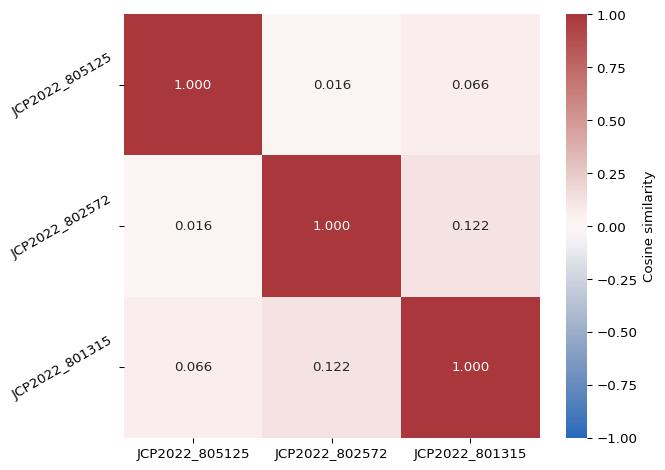

In [4]:
pandas_similarity = sampled_similarities.to_pandas()
pandas_similarity.index = pandas_similarity.columns
sns.heatmap(
    pandas_similarity,
    annot=True,
    fmt=".3f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap=sns.color_palette("vlag", as_cmap=True),
    cbar_kws={"label": "Cosine similarity"},
)
plt.yticks(rotation=30)
plt.tight_layout()

Off-diagonal entries compare different perturbations; the diagonal shows
self-similarity (approximately 1). This example illustrates querying
selected pairs, not a biological clustering analysis.